# Replicating Table 1 of Koijen & Levy (2026): sample description

The paper's Table 1 describes its 1,849 Q4 2025 earnings announcements. This notebook builds the same three panels for
our sample and puts them next to the paper's numbers.

- **Panel A:** number of events by reporting week × Fama-French 12 industry.
- **Panel B:** per week, mean / median / SD of the abnormal return and the surprise (% of price), and the R² of the
  baseline regression (return rank on surprise rank) within that week.
- **Panel C:** firm characteristics: price, abnormal return, analyst coverage, forecast dispersion, surprise.

**Choices, following the paper's notes to Table 1:**
- Sample: the in-sample calls of the pipeline's final dataset (`in_sample`), the same rows as the baseline regression.
- Weeks: calendar weeks (Monday-Sunday) of `event_date`, numbered from the first week with an event.
- Industry: Compustat SIC (`comp.company`, current value, not point-in-time) mapped with `signals/ff12.py`.
  The paper calls industry 11 "Fin"; `ff12.py` calls it "Money". PIPELINE.md §7.3 notes that the Health and Money
  ranges had not been checked against French's own file; all eleven defined industries (Other is the remainder)
  match French's `Siccodes12.txt` exactly (checked October 2026).
- Continuous variables (price, abnormal return, dispersion, surprise) are winsorized at the 1st and 99th percentiles.
  Coverage is a count and is left as is. The rank columns behind the R² are computed before winsorizing, as in the
  pipeline.
- Coverage = `n_estimates` (analysts in the consensus); dispersion = `consensus_std` (SD of their estimates, needs at
  least two). The paper does not define dispersion further; its median (0.04) matches `consensus_std`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from llm_based_earnings_surprise_ntam.pipeline.config import load_config, connect
from llm_based_earnings_surprise_ntam.llm.llm_common import MERGED
from llm_based_earnings_surprise_ntam.signals.ff12 import ff12_name, FF12_NAMES

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

# Same chart style as the other notebooks; categorical colors in fixed order
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300'
INK, INK2, SURFACE = '#0b0b0b', '#52514e', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK2, 'text.color': INK,
    'xtick.color': INK2, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e8e7e3', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.figsize': (10, 4), 'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

CFG = load_config()
INDUSTRIES = [('Fin' if n == 'Money' else n) for n in FF12_NAMES.values()]
MIN_N_R2 = 10   # weekly R² left blank below this many events (the paper leaves its 6-event week 1 blank)

## 1. Data

The final dataset plus each firm's SIC code from Compustat. The SIC pull runs once on WRDS and is cached in
`data/interim/compustat_sic.parquet`; delete that file to pull again.

In [2]:
SIC_CACHE = Path(CFG['paths']['interim']) / 'compustat_sic.parquet'
if SIC_CACHE.exists():
    sic = pd.read_parquet(SIC_CACHE)
else:
    db = connect(CFG)   # config's wrds_username, else $WRDS_USERNAME, else your pgpass user
    sic = db.raw_sql('select gvkey, sic from comp.company')
    db.close()
    sic.to_parquet(SIC_CACHE, index=False)

df = pd.read_parquet(MERGED)
s = df[df['in_sample']].merge(sic, on='gvkey', how='left')
s['industry'] = ff12_name(s['sic']).replace({'Money': 'Fin'})

week_start = s['event_date'].dt.to_period('W-SUN').dt.start_time
s['week'] = ((week_start - week_start.min()).dt.days // 7 + 1).astype(int)
WEEK_START = week_start.groupby(s['week']).first()

def winsorize(x, p=0.01):
    lo, hi = x.quantile([p, 1 - p])
    return x.clip(lo, hi)

for c in ['price', 'r_abn', 'sue', 'consensus_std']:
    s[f'{c}_w'] = winsorize(s[c])
s['surprise_pct_w'] = s['sue_w'] * 100   # surprise in % of price, as in the paper

print(f'{len(s):,} in-sample calls, {s.event_date.min():%Y-%m-%d} to {s.event_date.max():%Y-%m-%d}, '
      f'{s.week.max()} weeks | SIC missing for {s.industry.isna().sum()} calls')

2,584 in-sample calls, 2025-10-01 to 2025-12-24, 13 weeks | SIC missing for 0 calls


## 2. The paper's Table 1

Typed in from the paper (page 31).

In [3]:
paper_a = pd.DataFrame(
    [[2, 0, 2, 0, 0, 0, 0, 0, 0, 1, 0, 1],
     [0, 1, 4, 1, 1, 1, 0, 0, 1, 1, 36, 3],
     [8, 6, 26, 9, 6, 23, 3, 4, 10, 10, 89, 28],
     [16, 16, 62, 18, 12, 80, 7, 19, 39, 53, 77, 59],
     [35, 13, 57, 30, 30, 198, 17, 32, 57, 169, 82, 130],
     [6, 7, 21, 7, 3, 59, 6, 2, 16, 85, 16, 36]],
    index=pd.Index(range(1, 7), name='week'), columns=INDUSTRIES)
paper_a['Total'] = paper_a.sum(axis=1)
paper_a.loc['Total'] = paper_a.sum()

B_COLS = pd.MultiIndex.from_product([['r_abn', 's (%)'], ['Mean', 'Med.', 'SD']])
paper_b = pd.DataFrame(
    [[6, 0.06, 0.05, 0.12, 0.18, 0.17, 0.11, np.nan],
     [49, -0.00, -0.00, 0.07, 0.13, 0.12, 0.16, 0.00],
     [222, 0.00, -0.01, 0.08, 0.13, 0.10, 1.26, 0.16],
     [458, -0.01, -0.01, 0.10, 0.11, 0.10, 1.31, 0.05],
     [850, -0.01, -0.01, 0.12, -0.02, 0.14, 2.93, 0.05],
     [264, -0.01, -0.02, 0.12, -0.58, 0.15, 6.59, 0.03],
     [1849, -0.01, -0.01, 0.11, -0.05, 0.12, 3.28, 0.05]],
    index=pd.Index([1, 2, 3, 4, 5, 6, 'Total'], name='week'),
    columns=pd.MultiIndex.from_tuples([('', 'N')] + list(B_COLS) + [('', 'R²')]))

C_STATS = ['N', 'Mean', 'SD', 'P25', 'Median', 'P75']
paper_c = pd.DataFrame(
    [[1849, 71.41, 112.68, 8.67, 29.66, 79.98],
     [1849, -0.01, 0.11, -0.06, -0.01, 0.05],
     [1796, 8.30, 6.20, 3.00, 6.00, 12.00],
     [1694, 0.09, 0.16, 0.02, 0.04, 0.10],
     [1849, -0.05, 3.28, -0.03, 0.12, 0.44]],
    index=['Price', 'r_abn', 'Coverage', 'Dispersion', 's (%)'], columns=C_STATS)

## 3. Building the panels

In [4]:
def label_weeks(t):
    """Week numbers -> 'n (Mon dd)' so the calendar dates are visible."""
    return t.rename(index=lambda w: f'{w} ({WEEK_START[w]:%b %d})' if w in WEEK_START.index else w)

def make_panel_a(d):
    a = pd.crosstab(d['week'], d['industry']).reindex(columns=INDUSTRIES, fill_value=0)
    a['Total'] = a.sum(axis=1)
    a.loc['Total'] = a.sum()
    return a

def week_stats(g):
    r, x = g['r_abn_w'], g['surprise_pct_w']
    r2 = np.corrcoef(g['sue_pct_sample'], g['r_abn_pct'])[0, 1] ** 2 if len(g) >= MIN_N_R2 else np.nan
    return [len(g), r.mean(), r.median(), r.std(), x.mean(), x.median(), x.std(), r2]

def make_panel_b(d):
    rows = {w: week_stats(g) for w, g in d.groupby('week')}
    rows['Total'] = week_stats(d)
    return pd.DataFrame.from_dict(rows, orient='index', columns=paper_b.columns).rename_axis('week')

PANEL_C_VARS = {'Price': 'price_w', 'r_abn': 'r_abn_w', 'Coverage': 'n_estimates', 'Dispersion': 'consensus_std_w',
                's (%)': 'surprise_pct_w'}

def make_panel_c(d):
    def stats(x):
        x = x.dropna()
        return [len(x), x.mean(), x.std(), x.quantile(0.25), x.median(), x.quantile(0.75)]
    return pd.DataFrame({k: stats(d[c]) for k, c in PANEL_C_VARS.items()}, index=C_STATS).T

def side_by_side(paper, ours):
    """Paper and ours next to each other for every column."""
    t = pd.concat({'Paper': paper, 'Ours': ours}, axis=1)
    t = t.reorder_levels(list(range(1, t.columns.nlevels)) + [0], axis=1)   # source becomes the last level
    key = lambda c: c if isinstance(c, tuple) else (c,)
    return t[[key(c) + (src,) for c in paper.columns for src in ('Paper', 'Ours')]]

def fmt(t, ints=()):
    f = {c: ('{:,.0f}' if c in ints else '{:.2f}') for c in t.columns}
    return t.style.format(f, na_rep='')

ours_a, ours_b, ours_c = make_panel_a(s), make_panel_b(s), make_panel_c(s)

## 4. events by week and industry

Our sample covers every week of the quarter; the paper's has six. Weekly tables are shown separately, then the
industry totals side by side.

In [5]:
print('Ours')
display(label_weeks(ours_a).style.format('{:,.0f}'))
print('Paper')
display(paper_a.style.format('{:,.0f}'))

Ours


industry,NoDur,Durbl,Manuf,Enrgy,Chems,BusEq,Telcm,Utils,Shops,Hlth,Fin,Other,Total
week,,,,,,,,,,,,,
1 (Sep 29),2,1,0,0,1,0,0,0,0,1,0,0,5
2 (Oct 06),4,2,3,0,0,3,0,0,1,1,1,2,17
3 (Oct 13),0,0,4,2,0,1,0,0,3,2,48,4,64
4 (Oct 20),10,9,27,11,6,24,3,4,10,10,133,33,280
5 (Oct 27),17,18,72,23,15,94,8,19,47,64,163,72,612
6 (Nov 03),45,18,67,42,38,213,19,34,65,188,178,145,"1,052"
7 (Nov 10),6,4,20,10,2,78,9,4,14,81,33,47,308
8 (Nov 17),4,5,5,1,0,11,1,2,17,5,6,7,64
9 (Nov 24),2,0,5,0,0,17,0,0,9,3,3,1,40


Paper


,NoDur,Durbl,Manuf,Enrgy,Chems,BusEq,Telcm,Utils,Shops,Hlth,Fin,Other,Total
week,,,,,,,,,,,,,
1,2,0,2,0,0,0,0,0,0,1,0,1,6
2,0,1,4,1,1,1,0,0,1,1,36,3,49
3,8,6,26,9,6,23,3,4,10,10,89,28,222
4,16,16,62,18,12,80,7,19,39,53,77,59,458
5,35,13,57,30,30,198,17,32,57,169,82,130,850
6,6,7,21,7,3,59,6,2,16,85,16,36,264
Total,67,43,172,65,52,361,33,57,123,319,300,257,"1,849"


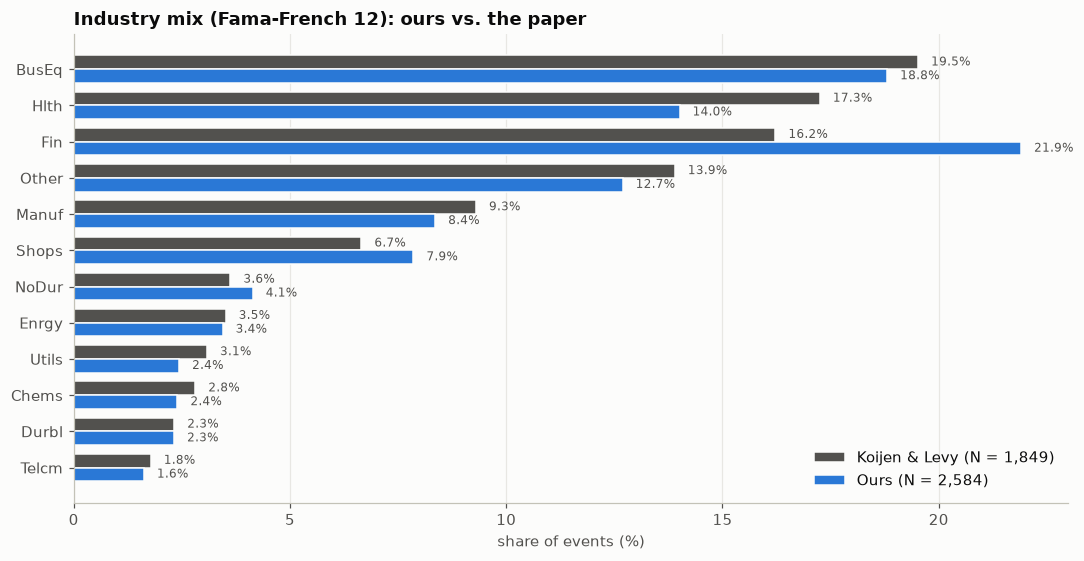

In [7]:
order = ind.sort_values('Paper %').index
pos = np.arange(len(order))
h = 0.38
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(pos + h / 2, ind.loc[order, 'Paper %'], height=h, color=INK2, edgecolor=SURFACE, linewidth=1,
        label=f'Koijen & Levy (N = {paper_a.loc["Total", "Total"]:,})')
ax.barh(pos - h / 2, ind.loc[order, 'Ours %'], height=h, color=BLUE, edgecolor=SURFACE, linewidth=1,
        label=f'Ours (N = {ours_a.loc["Total", "Total"]:,})')
for p, i in zip(pos, order):
    ax.text(ind.loc[i, 'Paper %'] + 0.3, p + h / 2, f'{ind.loc[i, "Paper %"]:.1f}%', va='center', fontsize=8, color=INK2)
    ax.text(ind.loc[i, 'Ours %'] + 0.3, p - h / 2, f'{ind.loc[i, "Ours %"]:.1f}%', va='center', fontsize=8, color=INK2)
ax.set_yticks(pos, order)
ax.set_xlabel('share of events (%)')
ax.grid(axis='y', visible=False)
ax.legend(loc='lower right')
ax.set_title('Industry mix (Fama-French 12): ours vs. the paper')
fig.tight_layout()
plt.show()